In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('https://data.insideairbnb.com/brazil/rj/rio-de-janeiro/2026-06-24/data/listings.csv.gz')
# df = pd.read_csv('https://data.insideairbnb.com/united-kingdom/england/london/2025-09-14/data/listings.csv.gz')
df.head(3)

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,1025196153924029661,https://www.airbnb.com/rooms/1025196153924029661,20260624212719,2026-06-25,city scrape,Quartos disponíveis no Recreio,NaN,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,546603190,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN
1,1697400829368754530,https://www.airbnb.com/rooms/1697400829368754530,20260624212719,2026-06-25,city scrape,Casa próxima a Floresta da Tijuca,Take a break to relax in this serene oasis in ...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,737983482,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN
2,42874066,https://www.airbnb.com/rooms/42874066,20260624212719,2026-06-25,city scrape,Alugo uma vaga para sexo feminino Recreio,NaN,NaN,https://a0.muscache.com/pictures/43e779d6-58df...,341395950,...,NaN,NaN,NaN,NaN,NaN,1,0,1,0,NaN


In [3]:
col_interesse = ['id', 'name', 'description', 'host_name', 'neighbourhood_cleansed', 'latitude', 'longitude', 'room_type', 'accommodates', 'bathrooms', 'bedrooms', 'beds', 'price']

room_trad = {'Entire home/apt': 'Todo o espaço',
             'Private room': 'Quarto privativo',
             'Shared room' : 'Quarto compartilhado'}

In [4]:
df_treatment = df[col_interesse].copy()
df_treatment['room_type'] = df_treatment['room_type'].map(room_trad)
df_treatment.head(3)

,id,name,description,host_name,neighbourhood_cleansed,latitude,longitude,room_type,accommodates,bathrooms,bedrooms,beds,price
0,1025196153924029661,Quartos disponíveis no Recreio,NaN,Ananda,Recreio dos Bandeirantes,-23.016320,-43.462606,Quarto privativo,2,4.0,2.0,2.0,NaN
1,1697400829368754530,Casa próxima a Floresta da Tijuca,Take a break to relax in this serene oasis in ...,Yuri,Alto da Boa Vista,-22.975611,-43.284655,Quarto privativo,2,1.0,1.0,1.0,$219.11
2,42874066,Alugo uma vaga para sexo feminino Recreio,NaN,Mabel,Recreio dos Bandeirantes,-23.022660,-43.492710,Quarto privativo,1,1.0,NaN,1.0,"$1,659.27"


In [5]:
df_treatment['price_cleaned'] = df_treatment['price'].str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(float)
# Bairros_perigosos = ['Centro', 'Bonsucesso', 'São Cristóvão', 'Caju', 'Pavuna', 'Complexo do Alemão', 'Complexo da Maré', 'Irajá', 'Piedade', 'Cascadura', 'Costas Barros', 'Senador Camará', 'Parada de Lucas', 'Brás de Pina', 'Vigário Geral', 'Barros Filhos', 'Complexo do Alemão', 'Triagem', 'Vila Kosmos']
# df_treatment['bairro_perigoso'] = df_treatment['neighbourhood_cleansed'].isin(Bairros_perigosos).astype(int)

In [6]:

df_outliers = df_treatment[df_treatment["price_cleaned"] >= 25000]
df_treatment = df_treatment[(df_treatment["price_cleaned"] <= 25000) | 
    (df_treatment["accommodates"] >= 6)
]

In [7]:
df_outliers.head(20)

,id,name,description,host_name,neighbourhood_cleansed,latitude,longitude,room_type,accommodates,bathrooms,bedrooms,beds,price,price_cleaned
1140,13616276,EXUBERANTE MANSAO,MANSAO LOCATED IN CLOSED CONDOMINIUM IN BARRA ...,Leonardo,Barra da Tijuca,-22.988540,-43.381010,Todo o espaço,10,8.0,5.0,6.0,"$42,417.70",42417.70
1650,12083803,Olympic Games House,Enjoy a memorable visit when you stay in this ...,Dani Clemes,Barra da Tijuca,-23.001423,-43.372544,Todo o espaço,16,NaN,5.0,12.0,"$45,647.08",45647.08
2540,1126967493931053898,Gigoiabreezy_,Come and hold your event in this amazing place...,Gadi,Barra da Tijuca,-23.003619,-43.309289,Todo o espaço,16,NaN,NaN,NaN,"$57,356.00",57356.00
3334,54006235,BARRA FIRST HOTEL,Easily access local hot spots from this hip pl...,Marcelo,Barra da Tijuca,-23.001140,-43.389200,Quarto privativo,2,1.0,1.0,1.0,"$51,353.00",51353.00
3595,1558281955757075479,Casas de Famosos para Locação na Barra da Tijuca,Celebrity homes for rent in Barra da Tijuca of...,Michael Ferraz,Barra da Tijuca,-23.003415,-43.375320,Quarto privativo,16,NaN,6.0,6.0,"$69,498.00",69498.00
4121,1608021143315341194,Apartamento novo,Get fun with the whole family in this stylish ...,Aecio Nanci,Barra da Tijuca,-23.000344,-43.422026,Todo o espaço,4,2.5,2.0,3.0,"$64,600.74",64600.74
6572,43424121,"Linda , cobertura no Méier",NaN,Leonardo,Cachambi,-22.894670,-43.271690,Quarto privativo,6,3.5,3.0,6.0,"$27,268.50",27268.50
11132,1577911814778847090,Refúgio Afeto - Uma nova experiência,"Complete studio, newly renovated and in front ...",Sambastay,Centro,-22.910720,-43.177403,Todo o espaço,2,1.0,1.0,1.0,"$50,100.00",50100.00
12701,1363679153931457978,Penthouse Rocha,Relax with the whole family in this quiet acco...,Alves,Copacabana,-22.970639,-43.191129,Todo o espaço,6,2.0,3.0,3.0,"$28,530.00",28530.00
14558,1123891762827377482,Rio001 - Luxury beachfront penthouse in Copaca...,Discover the pinnacle of luxury with this exce...,Latin Exclusive,Copacabana,-22.964219,-43.174903,Todo o espaço,16,11.5,10.0,11.0,"$27,362.00",27362.00


In [8]:
print("A quantidade de quartos com 0 camas é:", len(df_treatment[df_treatment["beds"] == 0]))

print("A quantidade total de anuncios é:", len(df_treatment))

df_treatment = df_treatment[df_treatment["beds"]>0]

A quantidade de quartos com 0 camas é: 0
A quantidade total de anuncios é: 45235


In [9]:
len(df_treatment.price_cleaned.dropna())/len(df.price.dropna())

0.9629787616182479

In [10]:
colunas_para_modelos = ['id', 'latitude', 'longitude', 'room_type', 'accommodates', 'bathrooms', 'bedrooms', 'beds', 'price_cleaned'] #review_scores_rating

In [11]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import SGDRegressor, Lasso
from sklearn.preprocessing import StandardScaler, RobustScaler, LabelEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn import preprocessing
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error, mean_absolute_error
from sklearn.base import clone
import matplotlib.pylab as plt
import seaborn as sns
import numpy as np
import plotly.express as px
RANDOM_SEED = 42

df_arvore_regressora = df_treatment[colunas_para_modelos].copy()

df_arvore_regressora.dropna(inplace=True)

In [12]:
enc = preprocessing.OneHotEncoder()
enc.fit(df_arvore_regressora[['room_type']])
one_hot = enc.transform(df_arvore_regressora[['room_type']]).toarray()
df_arvore_regressora[['Quarto compartilhado', 'Quarto privativo', 'Todo o espaço']] = one_hot

In [13]:
cat_cols = ['room_type']
num_cols = ['latitude', 'longitude', 'accommodates', 'bathrooms', 'bedrooms', 'beds'] #, 'review_scores_rating'

Text(0.5, 1.0, 'Correlation Heatmap')

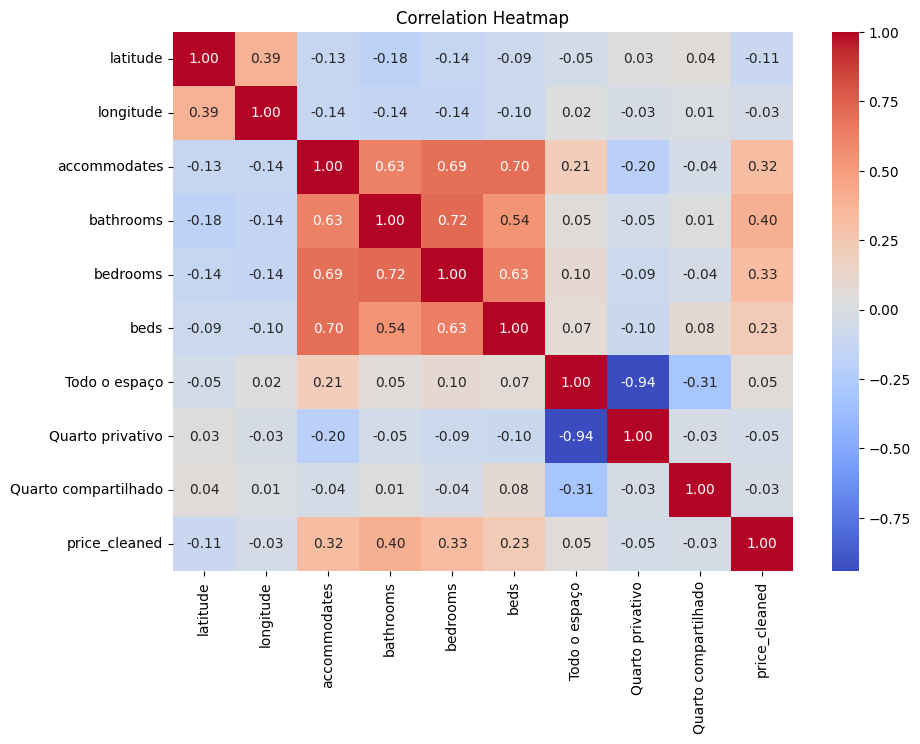

In [14]:
corr = df_arvore_regressora[[
    'latitude', 'longitude', 'accommodates', 
    'bathrooms', 'bedrooms', 'beds',
    'Todo o espaço', 'Quarto privativo', 'Quarto compartilhado',
    
    'price_cleaned',
    ]].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')

In [15]:
X = df_arvore_regressora.drop(columns=['price_cleaned'])
y = df_arvore_regressora['price_cleaned'].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_SEED)

In [16]:
from xgboost import XGBRegressor

precomputador_do_grupo =  ColumnTransformer(
    transformers=[
        ('cat', preprocessing.OneHotEncoder(sparse_output=False), cat_cols),
        ('num', 'passthrough', num_cols)
    ],
    remainder='drop')
    
pipeline_xgb = Pipeline(steps=[
    ('pre-processamento', precomputador_do_grupo),
    ('modelo', XGBRegressor(
        n_estimators=1000,
        max_depth=8,
        learning_rate=0.01,
        subsample=0.8,
        colsample_bytree=0.6,
        random_state=RANDOM_SEED,
        n_jobs=-1
    ))
])

pipeline_xgb.fit(X_train, y_train)
y_pred_xgb = pipeline_xgb.predict(X_test)

r2 = r2_score(y_test, y_pred_xgb)
rmse = root_mean_squared_error(y_test, y_pred_xgb)
print(f"R² Score: {r2:.4f}")
print(f"Root mean squared error: {rmse:.4f}")
print("Mean absolute error:", mean_absolute_error(y_test,y_pred_xgb))

R² Score: 0.3175
Root mean squared error: 2198.2570
Mean absolute error: 490.24845873461726
